# Highway Networks — Paper Exploration

**Goal:** Understand Highway Networks and prepare to implement a classifier for CIFAR-10.

### Notebook outline
1. Setup and environment
2. CIFAR-10 dataset
3. Highway Networks: theory
4. Gate-bias experiment
5. First Highway Layer implementation
6. Testing and gradient flow
7. Stacking Highway Layers
8. Convolutional Highway

## 1. Setup and environment

Import the libraries we need and confirm which device PyTorch will use.

In [11]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.14.1+cu126


## 2. CIFAR-10 dataset

### 2.1 Dataset overview

- 60,000 color images
- Image dimensions: 32 × 32 pixels
- 50,000 training images
- 10,000 test images
- 10 equally sized classes, with 6,000 images per class overall

Each image has three color channels: red, green, and blue.


Our network will take an image tensor with shape `(3, 32, 32)` and produce ten class scores.

The `3` represents RGB channels. A batch of images will have shape `(batch_size, 3, 32, 32)`.

### 2.2 Load the dataset

`ToTensor()` converts an image into a PyTorch tensor and scales pixel values to `[0, 1]`. The download will happen the first time you run this cell.

In [12]:
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="../data", train=True, download=True, transform=transform
)
test_dataset = torchvision.datasets.CIFAR10(
    root="../data", train=False, download=True, transform=transform
)

classes = train_dataset.classes
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", classes)

Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### 2.3 Inspect an example image

Each dataset item contains an image tensor and its numeric class label.

Image tensor shape: torch.Size([3, 32, 32])
Image tensor dtype: torch.float32
Pixel range: 0.0 to 1.0
Label: 6 — frog


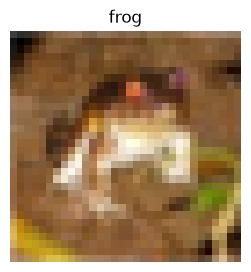

In [13]:
image, label = train_dataset[0]
print("Image tensor shape:", image.shape)
print("Image tensor dtype:", image.dtype)
print("Pixel range:", float(image.min()), "to", float(image.max()))
print("Label:", label, "—", classes[label])

plt.figure(figsize=(3, 3))
plt.imshow(image.permute(1, 2, 0))
plt.title(classes[label])
plt.axis("off")
plt.show()

### 2.4 Visualize sample images

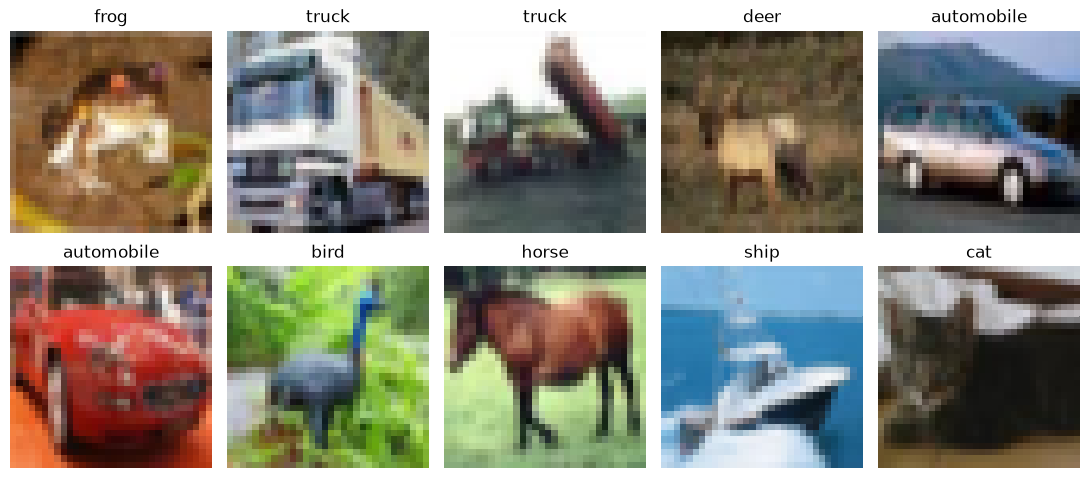

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Highway Networks - Theory

### 3.1 Highway layer equation

$$
y = H(x)T(x) + x(1-T(x))
$$

- $x$: original input
- $H(x)$: transformed input
- $T(x)$: transform gate, controlling the transformed contribution
- $1-T(x)$: carry gate, controlling the original-input contribution

Multiplication is **element-wise**; the input and transformed features must have matching shapes.

### 3.2 How the gates are learned

$$
H(x) = \operatorname{ReLU}(W_Hx+b_H)
$$

$$
T(x) = \sigma(W_Tx+b_T)
$$

$$
\sigma(z) = \frac{1}{1+e^{-z}}
$$

Weights and biases in the transform and gate are **learned during training**. Sigmoid values lie between 0 and 1.

| Transform gate $T(x)$ | Carry gate $1-T(x)$ | Behavior |
|---:|---:|---|
| 0.0 | 1.0 | Carry the input |
| 0.2 | 0.8 | Mostly carry |
| 0.5 | 0.5 | Mix both |
| 0.8 | 0.2 | Mostly transform |
| 1.0 | 0.0 | Transform the input |

### 3.3 Why use a negative gate bias?

If $W_Tx = 0$ and $b_T=-2$, then

$$
T(x)=\sigma(-2)\approx0.119,\qquad 1-T(x)\approx0.881.
$$

Thus the layer initially favors carrying information forward, making it **closer to an identity mapping** ($y\approx x$) in this illustrative case. This helps provide a more direct path for information and gradients in deep networks. Actual gate values also depend on $W_Tx$.

## 4. Gate-bias experiment

Observe how a negative gate bias favors the carry route when the weighted input is zero.

In [15]:
biases = torch.tensor([-5.0, -2.0, 0.0, 2.0, 5.0])
transform_gate = torch.sigmoid(biases)
carry_gate = 1 - transform_gate

for bias, t, c in zip(biases, transform_gate, carry_gate):
    print(
        f"bias = {bias.item():+4.1f} | "
        f"transform = {t.item():.3f} | "
        f"carry = {c.item():.3f}"
    )

bias = -5.0 | transform = 0.007 | carry = 0.993
bias = -2.0 | transform = 0.119 | carry = 0.881
bias = +0.0 | transform = 0.500 | carry = 0.500
bias = +2.0 | transform = 0.881 | carry = 0.119
bias = +5.0 | transform = 0.993 | carry = 0.007


## 5. Implement a fully connected Highway Layer

We start with `nn.Linear` to understand the gating mechanism. This is a learning exercise; we will later adapt the layer for image tensors.

In [16]:
import torch.nn as nn

class HighwayLayer(nn.Module):
    def __init__(self, features, gate_bias=-2.0):
        super().__init__()
        self.transform = nn.Linear(features, features)
        self.gate = nn.Linear(features, features)
        nn.init.constant_(self.gate.bias, gate_bias)

    def forward(self, x):
        H = torch.relu(self.transform(x))
        T = torch.sigmoid(self.gate(x))
        return H * T + x * (1 - T)

## 6. Test the Highway Layer

### 6.1 Verify input and output shapes

In [17]:
torch.manual_seed(42)
layer = HighwayLayer(features=4)

x = torch.tensor([
    [1.0, 2.0, 3.0, 4.0],
    [5.0, 6.0, 7.0, 8.0]
])
y = layer(x)

print("Input shape:", x.shape)
print("Output shape:", y.shape)
print("Input:\n", x)
print("Output:\n", y)
assert y.shape == x.shape

Input shape: torch.Size([2, 4])
Output shape: torch.Size([2, 4])
Input:
 tensor([[1., 2., 3., 4.],
        [5., 6., 7., 8.]])
Output:
 tensor([[1.3413, 1.9845, 2.9333, 3.0280],
        [5.2469, 5.9992, 6.9761, 4.1611]], grad_fn=<AddBackward0>)


### 6.2 Inspect transform and carry gates

In [18]:
with torch.no_grad():
    H = torch.relu(layer.transform(x))
    T = torch.sigmoid(layer.gate(x))
    C_gate = 1 - T

print("Transform gate T(x):\n", T)
print("Carry gate 1-T(x):\n", C_gate)
print("Sum of gates:\n", T + C_gate)
assert torch.allclose(T + C_gate, torch.ones_like(T))

Transform gate T(x):
 tensor([[1.6381e-01, 1.1186e-02, 3.6098e-02, 3.3210e-01],
        [9.3491e-02, 1.5846e-04, 6.9360e-03, 8.5379e-01]])
Carry gate 1-T(x):
 tensor([[0.8362, 0.9888, 0.9639, 0.6679],
        [0.9065, 0.9998, 0.9931, 0.1462]])
Sum of gates:
 tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.]])


### 6.3 Confirm gradient flow

Both sets of learnable parameters should receive gradients during backpropagation.

In [19]:
layer.zero_grad()
x_grad = torch.randn(2, 4, requires_grad=True)
y_grad = layer(x_grad)
loss = y_grad.sum()
loss.backward()

print("Input gradient:\n", x_grad.grad)
print("Transform weight gradient exists:", layer.transform.weight.grad is not None)
print("Gate weight gradient exists:", layer.gate.weight.grad is not None)

assert x_grad.grad is not None
assert layer.transform.weight.grad is not None
assert layer.gate.weight.grad is not None

Input gradient:
 tensor([[1.0234, 0.9845, 1.0138, 0.8022],
        [1.0752, 0.9183, 0.8901, 0.9838]])
Transform weight gradient exists: True
Gate weight gradient exists: True



## 7. Stacking Highway Layers

### 7.1 Why stack Highway Layers?

A deep neural network contains multiple layers, where each layer receives the output of the previous layer.

In a Highway Network, every layer decides how much information to transform and how much to preserve.

The equation for layer $l$ is:

$$
\boxed{
x_{l+1} = H_l(x_l)T_l(x_l) + x_l(1-T_l(x_l))
}
$$

Where:

- $x_l$ — input to layer $l$.
- $x_{l+1}$ — output of layer $l$.
- $H_l(x_l)$ — learned transformation.
- $T_l(x_l)$ — learned transform gate.
- $1-T_l(x_l)$ — carry gate.

Each Highway Layer has its own learnable parameters.

### 7.2 Information flow through multiple layers

For a network with three Highway Layers:

$$
x_1 = \operatorname{Highway}_1(x_0)
$$

$$
x_2 = \operatorname{Highway}_2(x_1)
$$

$$
x_3 = \operatorname{Highway}_3(x_2)
$$

Each layer can preserve useful features or transform them into new representations.

### 7.3 Why is this important for deep networks?

If the transform gate is close to zero:

$$
T_l(x_l) \approx 0
$$

Then:

$$
x_{l+1} \approx x_l
$$

The layer behaves approximately like an identity function.

**Benefits:**

- Information can pass through many layers without being heavily modified.
- The carry path provides a more direct route for gradients during backpropagation.
- The network can learn which layers and features need transformation.
- Negative transform gate biases help layers initially favor carrying information.

**Key idea:** Highway Networks can be made very deep because their gates help regulate information flow.

### 7.4 Important constraint

In our current implementation, input and output must have the same number of features:

$$
\operatorname{shape}(x_l) = \operatorname{shape}(x_{l+1})
$$

This is required for the element-wise addition in the Highway equation.


In [20]:
class HighwayNetwork(nn.Module):
    def __init__(self, features, num_layers=3, gate_bias=-2.0):
        super().__init__()

        self.layers = nn.ModuleList([
            HighwayLayer(features, gate_bias=gate_bias)
            for _ in range(num_layers)
        ])

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)

        return x

In [21]:
torch.manual_seed(42)

network = HighwayNetwork(
    features=4,
    num_layers=3,
    gate_bias=-2.0
)

x = torch.randn(2, 4)
y = network(x)

print("Input shape:", x.shape)
print("Output shape:", y.shape)
print("Number of Highway Layers:", len(network.layers))
print("Number of trainable parameters:",
      sum(p.numel() for p in network.parameters()))

assert y.shape == x.shape

Input shape: torch.Size([2, 4])
Output shape: torch.Size([2, 4])
Number of Highway Layers: 3
Number of trainable parameters: 120


In [22]:
torch.manual_seed(42)

x = torch.randn(1, 4)
current = x

print("Original input:")
print(current)

with torch.no_grad():
    for i, layer in enumerate(network.layers, start=1):
        current = layer(current)

        difference = (current - x).abs().mean().item()

        print(f"\nAfter Highway Layer {i}:")
        print(current)
        print(f"Mean absolute difference from original: {difference:.4f}")

Original input:
tensor([[0.3367, 0.1288, 0.2345, 0.2303]])

After Highway Layer 1:
tensor([[0.3718, 0.1224, 0.2075, 0.2401]])
Mean absolute difference from original: 0.0196

After Highway Layer 2:
tensor([[0.3684, 0.1263, 0.2183, 0.2132]])
Mean absolute difference from original: 0.0169

After Highway Layer 3:
tensor([[0.3649, 0.1136, 0.1939, 0.1901]])
Mean absolute difference from original: 0.0311


In [23]:
network.zero_grad()

x = torch.randn(2, 4, requires_grad=True)

y = network(x)
loss = y.pow(2).mean()

loss.backward()

print("Input receives gradients:", x.grad is not None)

for i, layer in enumerate(network.layers, start=1):
    print(
        f"Layer {i}: "
        f"transform gradient = {layer.transform.weight.grad is not None}, "
        f"gate gradient = {layer.gate.weight.grad is not None}"
    )

Input receives gradients: True
Layer 1: transform gradient = True, gate gradient = True
Layer 2: transform gradient = True, gate gradient = True
Layer 3: transform gradient = True, gate gradient = True



### 8.5 Experiment: Multiple Highway Layers

We implemented a `HighwayNetwork` containing multiple `HighwayLayer` modules.

**Observations:**

1. Multiple Highway Layers can be connected sequentially.
2. The input and output shapes remain unchanged.
3. Each layer has independent learnable transformation and gate parameters.
4. PyTorch can compute gradients through all Highway Layers.
5. Negative transform gate biases encourage the layers to initially preserve information.

**Conclusion:**

Stacking Highway Layers allows us to build a deep network in which every layer can dynamically choose how much information to transform or carry forward.

This architecture is designed to make optimization easier as network depth increases.



## 8. Convolutional Highway Layers

### 8.1 Why use convolutional Highway Layers?

Fully connected Highway Layers use `nn.Linear` and work with feature vectors.

For image data such as CIFAR-10, convolutional layers are more suitable because they preserve spatial structure and learn local image features.

A CIFAR-10 image has shape:

$$
(C,H,W)=(3,32,32)
$$

Where:

- $C$ — number of channels.
- $H$ — image height.
- $W$ — image width.

### 8.2 Convolutional Highway Equation

The Highway equation remains unchanged:

$$
\boxed{y=H(x)T(x)+x(1-T(x))}
$$

However, the transformation and transform gate now use convolutions:

$$
H(x)=\operatorname{ReLU}(\operatorname{Conv}_H(x))
$$

$$
T(x)=\sigma(\operatorname{Conv}_T(x))
$$

The carry gate is:

$$
C(x)=1-T(x)
$$

Both convolutions have independent learnable parameters.

### 8.3 Shape Requirements

For element-wise operations, $H(x)$, $T(x)$, and $x$ must have matching shapes.

In our implementation:

- Input channels equal output channels.
- Kernel size is $3\times3$.
- Padding is $1$.
- Stride is $1$.

This preserves the spatial dimensions:

$$
(B,C,H,W)\rightarrow(B,C,H,W)
$$

For example:

$$
(2,3,32,32)\rightarrow(2,3,32,32)
$$

### 8.4 Gate Initialization

We initialize the transform gate bias to a negative value:

$$
b_T=-2
$$

This encourages the layer to initially favor carrying information rather than transforming it.

**Key idea:** A Convolutional Highway Layer combines the spatial feature extraction of convolutions with the adaptive information flow of Highway Networks.


In [24]:
class ConvHighwayLayer(nn.Module):
    def __init__(self, channels, gate_bias=-2.0):
        super().__init__()

        self.transform = nn.Conv2d(
            in_channels=channels,
            out_channels=channels,
            kernel_size=3,
            padding=1
        )

        self.gate = nn.Conv2d(
            in_channels=channels,
            out_channels=channels,
            kernel_size=3,
            padding=1
        )

        nn.init.constant_(self.gate.bias, gate_bias)

    def forward(self, x):
        H = torch.relu(self.transform(x))
        T = torch.sigmoid(self.gate(x))

        y = H * T + x * (1 - T)

        return y

In [25]:
torch.manual_seed(42)

images = torch.stack([
    train_dataset[i][0]
    for i in range(4)
])

layer = ConvHighwayLayer(channels=3)
outputs = layer(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

assert outputs.shape == images.shape

Input shape: torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 3, 32, 32])


In [26]:
with torch.no_grad():
    H = torch.relu(layer.transform(images))
    T = torch.sigmoid(layer.gate(images))
    C = 1 - T

print("Transformation shape:", H.shape)
print("Transform gate shape:", T.shape)
print("Carry gate shape:", C.shape)

print("Mean transform gate:", T.mean().item())
print("Mean carry gate:", C.mean().item())

print("Gates sum to 1:",
      torch.allclose(T + C, torch.ones_like(T)))

Transformation shape: torch.Size([4, 3, 32, 32])
Transform gate shape: torch.Size([4, 3, 32, 32])
Carry gate shape: torch.Size([4, 3, 32, 32])
Mean transform gate: 0.0978870689868927
Mean carry gate: 0.9021129608154297
Gates sum to 1: True


In [27]:
layer.zero_grad()

images = images.clone().detach().requires_grad_(True)

outputs = layer(images)
loss = outputs.pow(2).mean()

loss.backward()

print("Input gradient exists:", images.grad is not None)
print("Transform gradient exists:",
      layer.transform.weight.grad is not None)
print("Gate gradient exists:",
      layer.gate.weight.grad is not None)

Input gradient exists: True
Transform gradient exists: True
Gate gradient exists: True



### 8.5 Experiment: Convolutional Highway Layer

We implemented a `ConvHighwayLayer` using two independent `nn.Conv2d` operations.

**Observations:**

1. The layer accepts four-dimensional image tensors.
2. Input and output shapes remain identical.
3. Transform and carry gates operate element-wise across channels and spatial positions.
4. The transform gate uses a sigmoid activation.
5. Negative gate bias initialization encourages information preservation.
6. Gradients can flow through both the transformation and gating operations.

**Conclusion:**

Convolutional Highway Layers extend the Highway Network architecture to image data while preserving the ability to carry or transform information.

We have now implemented and tested the main building blocks needed for a Highway-based CIFAR-10 classifier.
